# 04 · Manipulation check under the conditional edit (Results ¶8, Fig. S2b–c, Table `tab:manip`)

> **Provenance.** Built with the `repro-notebook` workflow (one executed notebook per experiment,
> every reported number checked against the produced one). Target paper: *Conversational Relevance in the
> Conjunction Fallacy Is Represented in Language Models* (`docs/paper/main_A.tex` in the authors' working
> repository; the released copy of the manuscript is the submission PDF). Companion documents:
> `REPRODUCTION_MANIFEST.md` (paper number → source CSV → producing script) and `REPRODUCTION_REPORT.md`
> (aggregated verdicts). Status legend: ✅ reproduced to the reported precision · ❌ does not match ·
> ⚠ presence check only · ⛔ cannot be recomputed from the released files.

## Source and code map

| id | what | data read here | original producing script |
|---|---|---|---|
| D1, D4 | joint IUT verdicts per strength cell | `additional_Qs/rq3_norm_manipulation_20260902/analysis/norm_manipulation_joint_verdicts.csv` | `additional_Qs/analysis/19_analyze_norm_manipulation.py` ← `run_rq3_norm_manipulation_gpu.py` |
| D2 | per-metric TOST / superiority, controls | `norm_manipulation_tests.csv` | `19_…` |
| D2 | PPL at α=2 | `additional_Qs/cf_rescue_fluency_posthoc/cells_annotated.csv` | `18_cf_rescue_fluency_posthoc.py` |
| D3 | separate P and C readouts of PC\|R | `nonjoint_fig23b/fig23b_nonjoint_readouts.csv` | `21_analyze_fig23b_nonjoint.py` |
| D4, D6 | equivalence margins | `norm_manipulation_margins.csv` | `19_…` |

Everything is **loaded**.

In [1]:
import sys, warnings
sys.path.insert(0, str(__import__('pathlib').Path.cwd() / 'notebooks'))
sys.path.insert(0, '.')
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from repro_utils import *
pd.set_option('display.width', 200, 'display.max_columns', 40, 'display.max_rows', 60,
              'display.float_format', lambda v: f'{v:,.4f}')
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': .25,
                     'axes.spines.top': False, 'axes.spines.right': False, 'font.size': 9})
print('repository root:', ROOT.name)
C = Checks('04_manipulation_check')

repository root: release


## D1 · The relevance edit leaves the norms inside their preregistered margin; the evidential edit does not move them as predicted

Reported: $R_{|PC}$ both norms equivalent in **8/12** strength cells; $PC_{|R}$ both moving as predicted in **0/13**;
every $R_{|PC}$ ablation cell passes (**5/5**, including $\lambda=1$); all four failures are injections at $\alpha\ge1$.

In [2]:
jv = read(MAN / 'norm_manipulation_joint_verdicts.csv'); jv['model'] = jv.model_id.str.split('/').str[-1]
tally = jv.groupby(['target_direction', 'joint_criterion']).joint_pass.agg(['sum', 'size']); display(tally)
r = jv[jv.target_direction == 'R_given_PC']; pc = jv[jv.target_direction == 'PC_given_R']
C.frac('D1', 'Results ¶8', 'R|PC: P and C both equivalent', '8/12', r.joint_pass.sum(), len(r), rel(MAN / 'norm_manipulation_joint_verdicts.csv'))
C.frac('D1', 'Results ¶8', 'PC|R: P and C both move as predicted', '0/13', pc.joint_pass.sum(), len(pc))
rabl = r[r.stage == 'ABL']; C.frac('D1', 'Results ¶8', 'R|PC ablation cells passing', '5/5', rabl.joint_pass.sum(), len(rabl))
fails = r[~r.joint_pass]; C.frac('D1', 'Results ¶8', 'R|PC failures that are injections at α≥1', '4/4', ((fails.stage == 'ADD') & (fails.strength >= 1)).sum(), len(fails))
display(r[['model', 'task', 'stage', 'strength', 'P_mean', 'P_p', 'C_mean', 'C_p', 'joint_iut_p', 'joint_pass']].sort_values(['stage', 'strength', 'model']))

,,sum,size
target_direction,joint_criterion,,
PC_given_R,P&C oriented superiority,0,13
R_given_PC,P&C TOST equivalence,8,12


,model,task,stage,strength,P_mean,P_p,C_mean,C_p,joint_iut_p,joint_pass
23,Phi-4-mini-reasoning,3,ABL,0.5000,-0.0143,0.0000,0.0048,0.0000,0.0000,True
7,Qwen3-4B,3,ABL,0.5000,0.0019,0.0000,0.0004,0.0000,0.0000,True
24,Phi-4-mini-reasoning,3,ABL,1.0000,-0.0256,0.0000,0.0105,0.0000,0.0000,True
6,Qwen3-4B,2,ABL,1.0000,0.0004,0.0000,0.0531,0.0000,0.0000,True
8,Qwen3-4B,3,ABL,1.0000,0.0004,0.0000,0.0007,0.0000,0.0000,True
18,Phi-4-mini-instruct,2,ADD,0.5000,-0.0100,0.0000,-0.0382,0.0000,0.0000,True
21,Phi-4-mini-instruct,3,ADD,0.5000,-0.0280,0.0000,-0.0263,0.0000,0.0000,True
2,Qwen2.5-Math-1.5B,3,ADD,0.5000,-0.0162,0.0004,0.0035,0.0014,0.0014,True
19,Phi-4-mini-instruct,2,ADD,1.0000,-0.0713,0.0014,-0.1567,0.9961,0.9961,False
22,Phi-4-mini-instruct,3,ADD,1.0000,-0.0953,0.0164,-0.1277,0.9027,0.9027,False


## D2 · The constrained controls separate two causes of leakage

Reported: at $\alpha=0.5$ nothing moves the norms; at $\alpha=1$ only the target moves them and random directions stay
equivalent in **12/12**; at $\alpha=2$ random directions move them too and perplexity rises **35.7 %**.
(The paper attributes the leakage to $\cos(v_R, v_P)=.335$; that cosine is not stored in any released file.)

In [3]:
tt = read(MAN / 'norm_manipulation_tests.csv'); rc = tt[tt.target_direction == 'R_given_PC']
piv = rc.groupby(['stage', 'strength', 'control_role']).equivalent.agg(['sum', 'size']); piv['ratio'] = piv['sum'].astype(str) + '/' + piv['size'].astype(str)
display(piv['ratio'].unstack('control_role'))
rnd1 = rc[(rc.strength == 1.0) & (rc.control_role == 'random')]
C.frac('D2', 'Results ¶8', 'random directions equivalent at strength 1 (P and C tests, injection and ablation cells)', '12/12', rnd1.equivalent.sum(), len(rnd1), rel(MAN / 'norm_manipulation_tests.csv'))
rnd05 = rc[(rc.strength == 0.5) & (rc.control_role != 'target')]; tg05 = rc[(rc.strength == 0.5) & (rc.control_role == 'target')]
C.frac('D2', 'Results ¶8', 'at strength 0.5 nothing moves the norms (target tests equivalent)', f'{len(tg05)}/{len(tg05)}', tg05.equivalent.sum(), len(tg05))
rnd2 = rc[(rc.strength == 2.0) & (rc.control_role == 'random')]
C.frac('D2', 'Results ¶8', 'at α=2 random directions move the norms too (equivalent tests)', '0/' + str(len(rnd2)), rnd2.equivalent.sum(), len(rnd2))
ld = read(CFP / 'ladder.csv'); a2 = ld[(ld.stage == 'ADD') & (ld.strength == 2.0)].iloc[0]
C.num('D2', 'Results ¶8', 'perplexity increase at α=2 (median over the 24 injection cells)', '35.7%', 100 * a2.ppl_median, rel(CFP / 'ladder.csv'),
      note=f'max {100*a2.ppl_max:.0f}% (Phi-4-mini-reasoning); the paper quotes the median')
C.blocked('D5', 'Results ¶8 / Discussion ¶2', 'cos(v_R, v_P) = .335', '.335', 'not stored in any released CSV; would need the activations (not shipped)')

control_role   random shuffle target
stage strength                      
ABL   0.5000      4/4     4/4    4/4
      1.0000      6/6     6/6    6/6
ADD   0.5000      6/6     6/6    6/6
      1.0000      6/6     4/6    2/6
      2.0000      0/2     0/2    0/2

## D3 · Under $PC_{|R}$ the two norms move in opposite directions

Reported: $C$ rose as predicted in **6/13** cells; $\rho$ fell in all **nine** Qwen3 injection cells, against the prediction;
controls at chance, random **0/13** and shuffle **2/13**. Source: separate P and C readouts (no AND gate).

In [4]:
nj = read(MAN / 'nonjoint_fig23b/fig23b_nonjoint_readouts.csv'); nj['model'] = nj.model_id.str.split('/').str[-1]
pc_pass = nj.pivot_table(index='control_role', columns='metric', values='pass_raw_p', aggfunc='sum'); pc_n = nj.pivot_table(index='control_role', columns='metric', values='pass_raw_p', aggfunc='size')
display(pc_pass.astype(int).astype(str) + '/' + pc_n.astype(str))
tgt = nj[nj.control_role == 'target']
C.frac('D3', 'Results ¶8', 'PC|R target cells where C rises as predicted', '6/13', tgt[tgt.metric == 'C'].pass_raw_p.sum(), (tgt.metric == 'C').sum(), rel(MAN / 'nonjoint_fig23b/fig23b_nonjoint_readouts.csv'))
q = tgt[(tgt.metric == 'P') & (tgt.stage == 'ADD') & tgt.model.str.startswith('Qwen3')]
C.frac('D3', 'Results ¶8', 'Qwen3 injection cells where ρ moves against the prediction', '9/9', (q.oriented_delta_did < 0).sum(), len(q))
for role, exp in [('random', '0/13'), ('shuffle', '2/13')]:
    c = nj[nj.control_role == role]
    per_metric = c.groupby('metric').pass_raw_p.sum().to_dict()
    C.frac('D3', 'Results ¶8', f'{role} control cells passing the oriented test on C (separate readout)', exp, per_metric.get('C', 0), (c.metric == 'C').sum(), rel(MAN / 'nonjoint_fig23b/fig23b_nonjoint_readouts.csv'),
           note=f'per-metric counts P {per_metric.get("P", 0)}, C {per_metric.get("C", 0)}; joint (both norms) {int(c.groupby(["model_id", "task", "stage", "strength"]).pass_raw_p.all().sum())}')
display(tgt.pivot_table(index=['model', 'task', 'stage', 'strength'], columns='metric', values='oriented_delta_did'))

metric,C,P
control_role,,
random,0/13,0/13
shuffle,2/13,2/13
target,6/13,2/13


metric                                           C       P
model                  task stage strength                
Qwen2.5-Math-1.5B      2    ABL   0.5000   -0.0004 -0.0026
                                  1.0000   -0.0005 -0.0050
Qwen3-4B               2    ABL   0.5000    0.0146  0.0381
                                  1.0000    0.0123  0.1729
                       3    ADD   0.5000    0.0207 -0.0634
                                  1.0000    0.0381 -0.1071
                                  2.0000    0.0670 -0.1715
Qwen3-4B-Instruct-2507 2    ADD   0.5000    0.0687 -0.0268
                                  1.0000    0.1074 -0.0730
                                  2.0000    0.0429 -0.2215
                       3    ADD   0.5000    0.0358 -0.0483
                                  1.0000    0.0501 -0.0985
                                  2.0000   -0.0151 -0.1774

## D4 · Table `tab:manip` (all 25 strength cells) and D6 · the equivalence margins

Reported margins: Qwen2.5-Math $\delta_\rho=0.025$, $\delta_C=0.009$; Qwen3-4B $0.218$, $0.118$; Qwen3-4B-Instruct $0.285$, $0.257$.
The paper prints no margins for the two Phi models although they appear in the table; they are shown here.

In [5]:
display(jv[['model', 'task', 'stage', 'target_direction', 'strength', 'P_mean', 'P_p', 'C_mean', 'C_p', 'joint_pass']].sort_values(['target_direction', 'model', 'task', 'stage', 'strength']).reset_index(drop=True))
C.frac('D4', 'Table tab:manip', 'strength cells in the table', '25/25', len(jv), 25)
mg = read(MAN / 'norm_manipulation_margins.csv'); mg['model'] = mg.model_id.str.split('/').str[-1]; display(mg.pivot_table(index='model', columns='metric', values='margin'))
for m, dp, dc in [('Qwen2.5-Math-1.5B', '0.025', '0.009'), ('Qwen3-4B', '0.218', '0.118'), ('Qwen3-4B-Instruct-2507', '0.285', '0.257')]:
    C.num('D6', 'Table tab:manip caption', f'margin δ_ρ, {m}', dp, mg[(mg.model == m) & (mg.metric == 'P')].margin.iloc[0], rel(MAN / 'norm_manipulation_margins.csv'))
    C.num('D6', 'Table tab:manip caption', f'margin δ_C, {m}', dc, mg[(mg.model == m) & (mg.metric == 'C')].margin.iloc[0])
thetas = sorted(tt.theta.unique())
C.presence('D7', 'Deviation 6', 'θ=0.5 sensitivity margin was fixed; results not printed in the paper', 'θ ∈ {0.25, 0.5}', f'θ values present in tests.csv: {thetas}')

,model,task,stage,target_direction,strength,P_mean,P_p,C_mean,C_p,joint_pass
0,Qwen2.5-Math-1.5B,2,ABL,PC_given_R,0.5000,0.0026,0.9209,0.0004,0.6852,False
1,Qwen2.5-Math-1.5B,2,ABL,PC_given_R,1.0000,0.0050,0.9242,0.0005,0.6891,False
2,Qwen3-4B,2,ABL,PC_given_R,0.5000,-0.0381,0.0018,-0.0146,0.0515,False
3,Qwen3-4B,2,ABL,PC_given_R,1.0000,-0.1729,0.0000,-0.0123,0.2149,False
4,Qwen3-4B,3,ADD,PC_given_R,0.5000,-0.0634,0.9999,0.0207,0.0004,False
5,Qwen3-4B,3,ADD,PC_given_R,1.0000,-0.1071,0.9998,0.0381,0.0004,False
6,Qwen3-4B,3,ADD,PC_given_R,2.0000,-0.1715,0.9999,0.0670,0.0003,False
7,Qwen3-4B-Instruct-2507,2,ADD,PC_given_R,0.5000,-0.0268,0.9044,0.0687,0.0099,False
8,Qwen3-4B-Instruct-2507,2,ADD,PC_given_R,1.0000,-0.0730,0.9572,0.1074,0.0380,False
9,Qwen3-4B-Instruct-2507,2,ADD,PC_given_R,2.0000,-0.2215,0.9928,0.0429,0.3440,False


metric,C,P
model,,
Phi-4-mini-instruct,0.1016,0.1745
Phi-4-mini-reasoning,0.1128,0.1464
Qwen2.5-Math-1.5B,0.0090,0.0252
Qwen3-4B,0.1182,0.2178
Qwen3-4B-Instruct-2507,0.2572,0.2845


## Figure S2

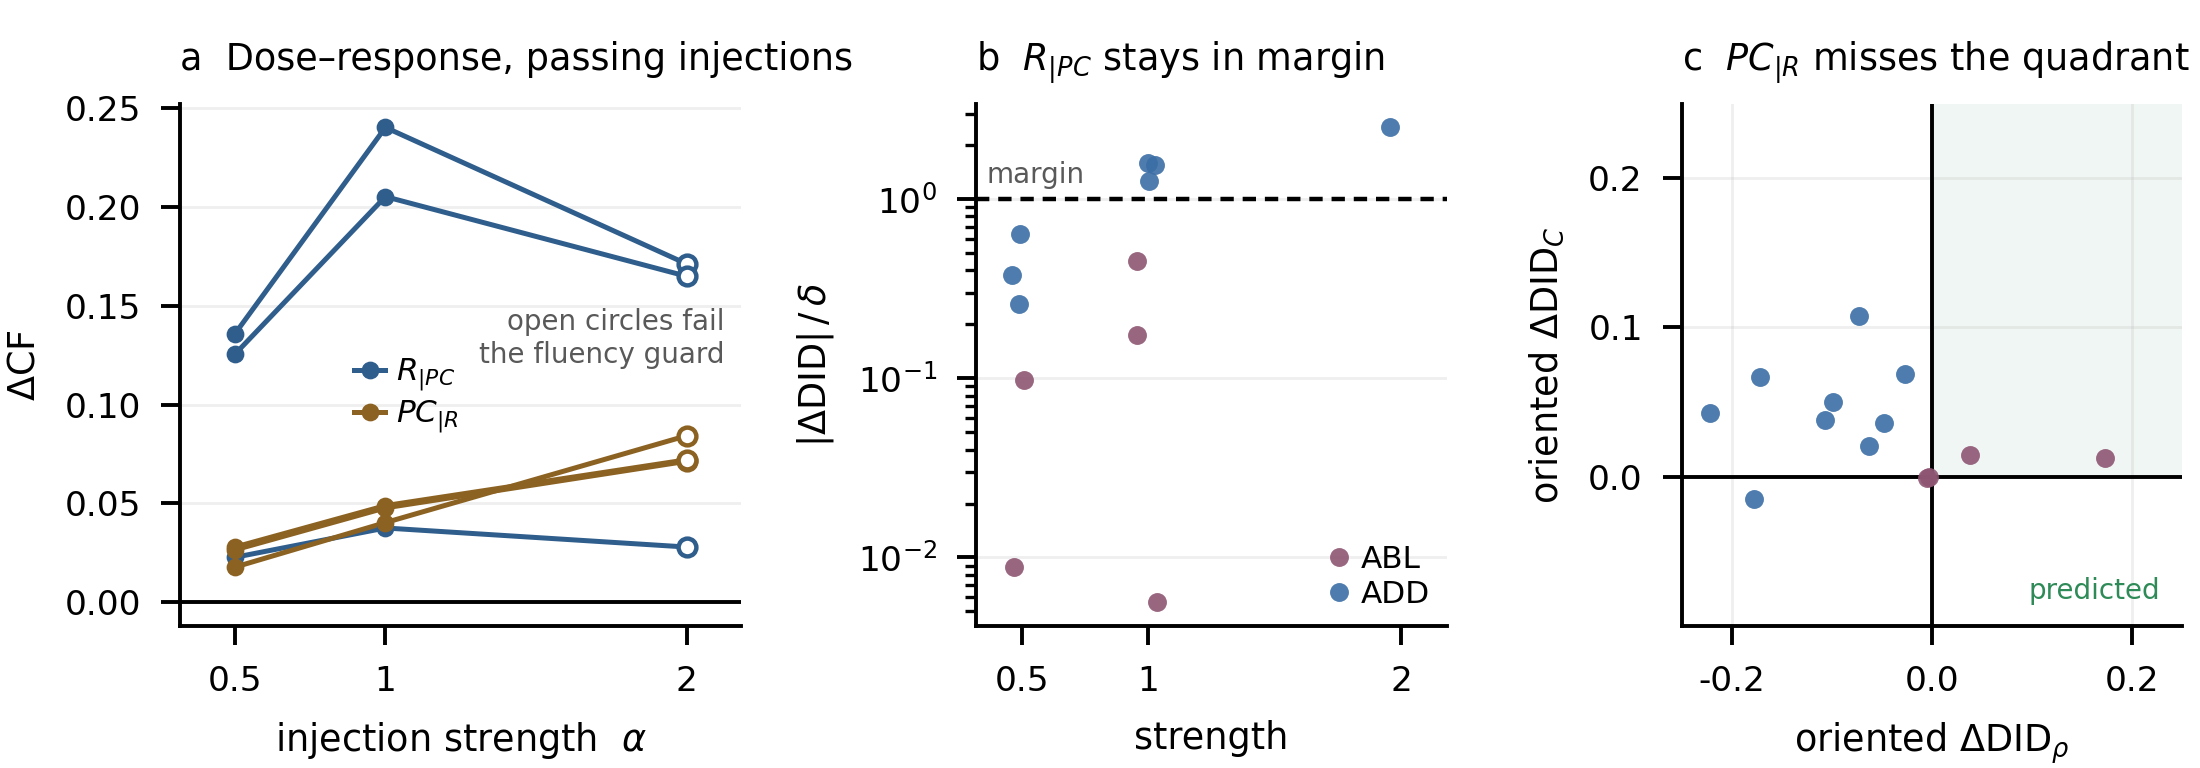

In [6]:
show_figure('figS2_intervention_detail.png', 900)

## Reproduction table for this notebook

In [7]:
df = C.show(); C.save('04')

04_manipulation_check: ✅ 19 · ⛔ 1 · ⚠ 1


id,section,analysis,reported,produced,status,note
D1,Results ¶8,R|PC: P and C both equivalent,8/12,8/12,✅,
D1,Results ¶8,PC|R: P and C both move as predicted,0/13,0/13,✅,
D1,Results ¶8,R|PC ablation cells passing,5/5,5/5,✅,
D1,Results ¶8,R|PC failures that are injections at α≥1,4/4,4/4,✅,
D2,Results ¶8,"random directions equivalent at strength 1 (P and C tests, injection and ablation cells)",12/12,12/12,✅,
D2,Results ¶8,at strength 0.5 nothing moves the norms (target tests equivalent),10/10,10/10,✅,
D2,Results ¶8,at α=2 random directions move the norms too (equivalent tests),0/2,0/2,✅,
D2,Results ¶8,perplexity increase at α=2 (median over the 24 injection cells),35.7%,+35.71,✅,max 500% (Phi-4-mini-reasoning); the paper quotes the median
D5,Results ¶8 / Discussion ¶2,"cos(v_R, v_P) = .335",.335,—,⛔,not stored in any released CSV; would need the activations (not shipped)
D3,Results ¶8,PC|R target cells where C rises as predicted,6/13,6/13,✅,


saved notebooks/_checks_04.csv
